# Lane Keeping Assist Video Analysis

This notebook walks through a classical lane-perception demo using OpenCV and NumPy. I start with grayscale edge evidence, then straighten the road with a perspective transform, search for lane pixels, fit curves, and smooth the results over time. The goal is to understand each step by looking at its output, not to control a vehicle or make safety decisions.

The sample clip is `input_videos/road-video-dubai.mp4`. The notebook needs Python 3.9 or newer, `opencv-python`, `numpy`, and Matplotlib for displaying images. It creates the input and output folders if they are missing.

## 1. Import Libraries and Setup

I import the tools for image processing, arrays, plotting, and storing recent fits. Then I set the project paths and put the ROI and gradient thresholds into one `LaneConfig`, so the camera settings are easy to find and adjust.

**Assumptions:** Run the notebook from the project folder. The sample clip is expected in `input_videos/`; `FRAME_LIMIT` is set for a quicker test and can be changed to `None` for a full pass.

**Complexity:** Setup is effectively constant-time. The ROI uses proportions instead of fixed pixels, which handles different resolutions, but another camera angle still needs different proportions.

In [2]:
from collections import deque
from dataclasses import dataclass
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
INPUT_DIR = ROOT / "input_videos"
OUTPUT_DIR = ROOT / "output_videos"
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

VIDEO_PATH = INPUT_DIR / "road-video-dubai.mp4"
FRAME_LIMIT = 180  # Set to None to process the complete video.

@dataclass
class LaneConfig:
    roi_top: float = 0.74
    roi_bottom: float = 0.97
    roi_top_left: float = 0.46
    roi_top_right: float = 0.54
    roi_bottom_left: float = 0.34
    roi_bottom_right: float = 0.68
    gradient_percentile: float = 99.5
    gradient_threshold: int = 28
    lane_width_min: float = 0.30
    lane_width_max: float = 0.70

CONFIG = LaneConfig()


def show_image(image, title, cmap=None, figsize=(12, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.show()


def bgr_to_rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print(f"Project: {ROOT}")
print(f"Input video: {VIDEO_PATH}")
print(f"Video exists: {VIDEO_PATH.is_file()}")
print(f"Outputs: {OUTPUT_DIR}")

Project: /Users/rireri/Desktop/Work space/Lane_Keeping VA
Input video: /Users/rireri/Desktop/Work space/Lane_Keeping VA/input_videos/road-video-dubai.mp4
Video exists: True
Outputs: /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos


## 2. Load and Inspect Input Video

**Load and Inspect :** I look for the named Dubai clip first and use the first sorted MP4 as a fallback. I open the chosen file, read its basic video details and first frame, then display that frame. Seeing the camera view early helps me judge whether the ROI makes sense.

**Assumptions:** OpenCV can decode the file and read at least one frame. If several clips are present and the named sample is missing, the fallback may choose a different one, so I check the printed filename.

**Complexity:** This reads only one frame rather than loading the full video into memory. The capture is released as soon as the inspection frame is obtained.

Selected: road-video-dubai.mp4
Size: 1920 x 1080; fps: 30.00; frames: 906


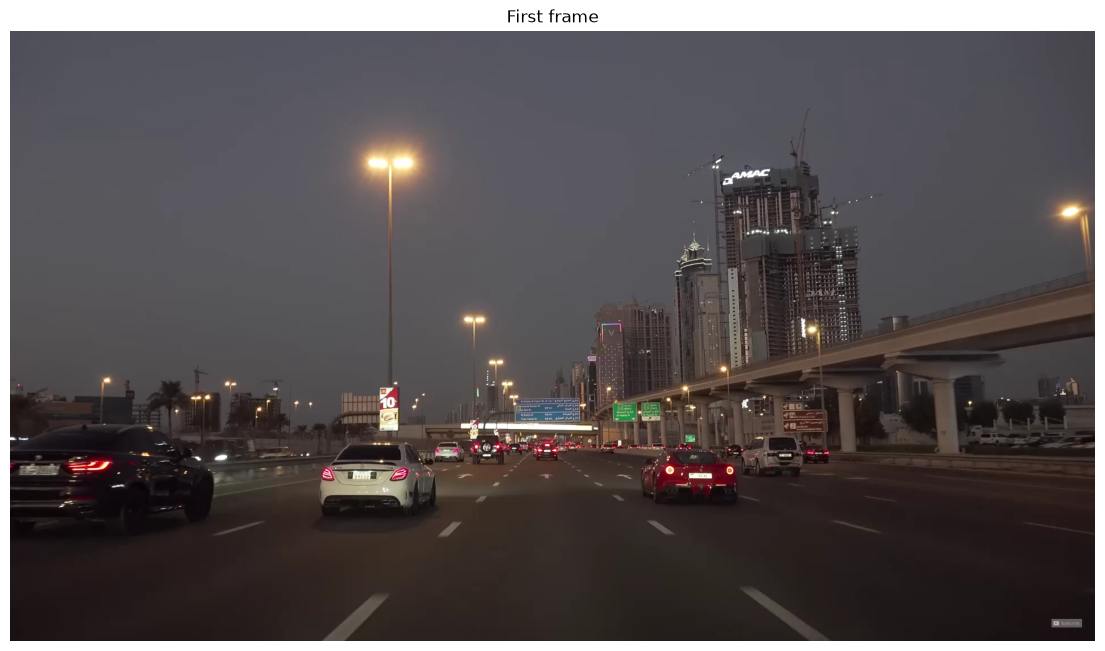

In [12]:
available_videos = sorted(INPUT_DIR.glob("*.mp4"))
if VIDEO_PATH.is_file():
    selected_video = VIDEO_PATH
elif available_videos:
    selected_video = available_videos[0]
else:
    raise FileNotFoundError(f"No MP4 files found in {INPUT_DIR}")

capture = cv2.VideoCapture(str(selected_video))
if not capture.isOpened():
    raise RuntimeError(f"OpenCV could not open {selected_video}")

fps = capture.get(cv2.CAP_PROP_FPS)
frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
frame_width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
read_ok, first_frame = capture.read()
capture.release()

if not read_ok:
    raise RuntimeError(f"The video opened but no frame could be read from {selected_video}")

print(f"Selected: {selected_video.name}")
print(f"Size: {frame_width} x {frame_height}; fps: {fps:.2f}; frames: {frame_count}")
show_image(bgr_to_rgb(first_frame), "First frame", figsize=(14, 8))

## 3. Gradient-Based Lane Evidence

I convert the frame to grayscale, use CLAHE to bring out local contrast, and apply an x-direction Sobel filter to highlight vertical edges. I scale the response using values inside the road ROI, threshold it into a binary mask, and close tiny gaps. The plots let me compare the edge strength with the pixels that move on to the detector.

**Assumptions:** Lane paint creates useful vertical edges and falls inside the ROI. With color cues removed, headlights, cars, and barriers can look like lane paint too.

**Complexity:** Filtering and thresholding operate over the image, so their cost is roughly proportional to its pixel count, $O(HW)$. The adaptive percentile responds to lighting changes, but cannot tell what caused an edge.

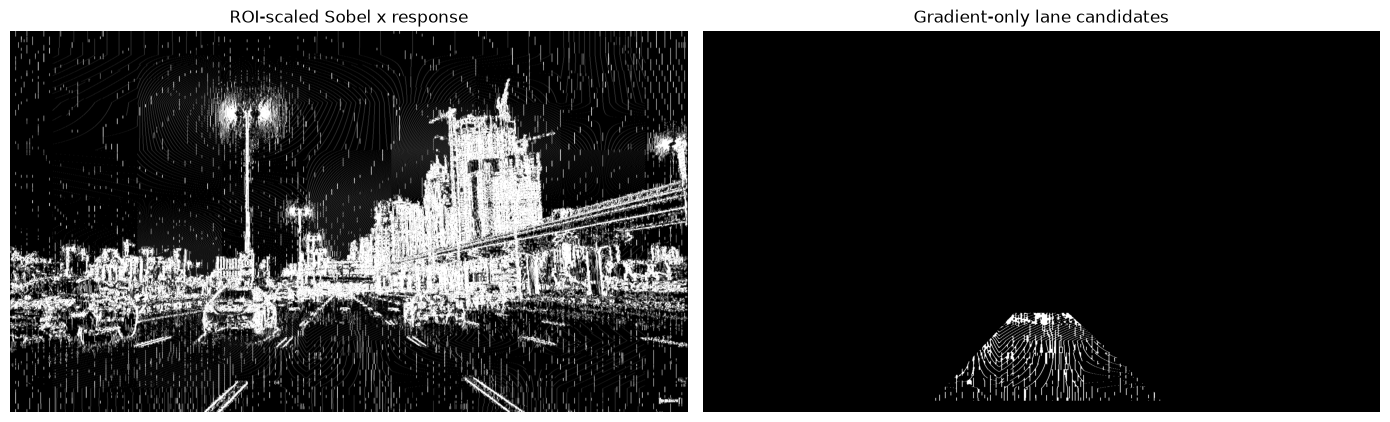

In [4]:
def roi_vertices(width, height, config=CONFIG):
    return np.array(
        [[
            (int(width * config.roi_bottom_left), int(height * config.roi_bottom)),
            (int(width * config.roi_top_left), int(height * config.roi_top)),
            (int(width * config.roi_top_right), int(height * config.roi_top)),
            (int(width * config.roi_bottom_right), int(height * config.roi_bottom)),
        ]],
        dtype=np.int32,
    )


def road_roi_mask(shape, config=CONFIG):
    height, width = shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, roi_vertices(width, height, config), 255)
    return mask


def gradient_lane_mask(frame, config=CONFIG):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    abs_sobel = np.abs(sobel_x)
    roi = road_roi_mask(frame.shape) > 0
    roi_values = abs_sobel[roi]
    if roi_values.size == 0:
        empty = np.zeros(gray.shape, dtype=np.uint8)
        return empty, empty

    scale = float(np.percentile(roi_values, config.gradient_percentile))
    if scale <= 0:
        empty = np.zeros(gray.shape, dtype=np.uint8)
        return empty, empty

    scaled = np.clip(abs_sobel * (255.0 / scale), 0, 255).astype(np.uint8)
    binary = cv2.inRange(scaled, config.gradient_threshold, 255)
    binary = cv2.bitwise_and(binary, road_roi_mask(frame.shape))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    return binary, scaled


mask, gradient_preview = gradient_lane_mask(first_frame)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(gradient_preview, cmap="gray")
axes[0].set_title("ROI-scaled Sobel x response")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Gradient-only lane candidates")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 4. Perspective Transform (Bird's-Eye View)

I map the road's four-point trapezoid to a rectangle, which gives a top-down view of the candidate mask. The forward transform is used for lane search, and its inverse puts fitted points back onto the original camera frame. The ROI outline is displayed so I can check the selected road area.

**Assumptions:** The camera stays fixed and the road surface is close enough to flat for one perspective transform. The ROI corners must follow the lane region; incorrect corners distort the search and the final overlay.

**Complexity:** The matrices are calculated once for this frame size. Warping processes the image pixels, so it takes roughly $O(HW)$ work.

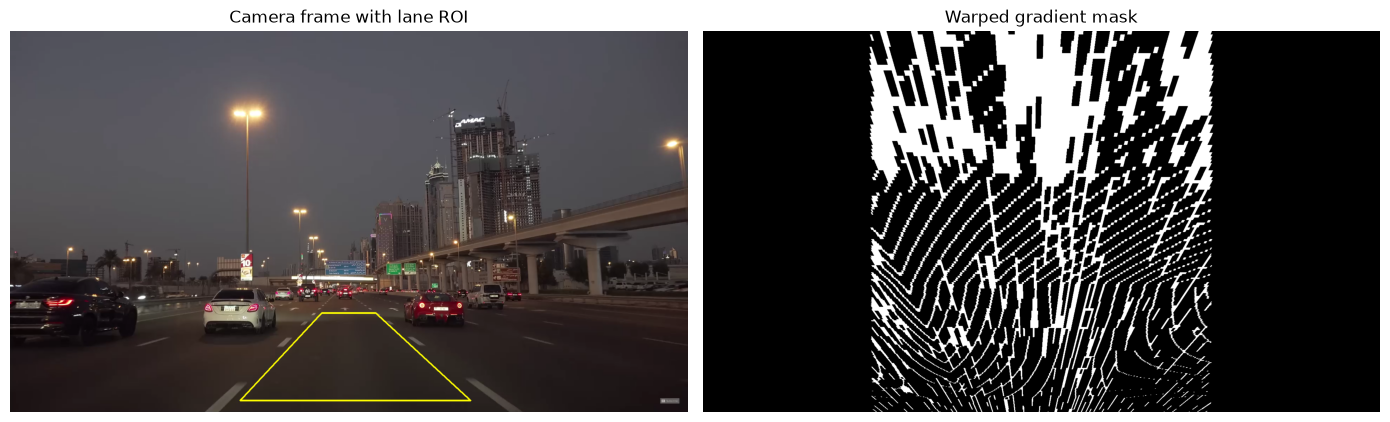

In [5]:
def perspective_matrices(width, height, config=CONFIG):
    roi = roi_vertices(width, height, config)[0]
    source = np.float32([roi[1], roi[2], roi[3], roi[0]])
    destination = np.float32([
        [width * 0.25, 0],
        [width * 0.75, 0],
        [width * 0.75, height - 1],
        [width * 0.25, height - 1],
    ])
    forward = cv2.getPerspectiveTransform(source, destination)
    inverse = cv2.getPerspectiveTransform(destination, source)
    return forward, inverse


def warp_to_birdseye(image, matrix):
    height, width = image.shape[:2]
    return cv2.warpPerspective(image, matrix, (width, height), flags=cv2.INTER_NEAREST)


perspective_matrix, inverse_perspective_matrix = perspective_matrices(frame_width, frame_height)
birdseye_mask = warp_to_birdseye(mask, perspective_matrix)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
roi_preview = first_frame.copy()
cv2.polylines(roi_preview, roi_vertices(frame_width, frame_height), True, (0, 255, 255), 3)
axes[0].imshow(bgr_to_rgb(roi_preview))
axes[0].set_title("Camera frame with lane ROI")
axes[1].imshow(birdseye_mask, cmap="gray")
axes[1].set_title("Warped gradient mask")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Lane Detection with Sliding Windows and Polynomial Fit

I use a histogram of the lower part of the warped mask to choose starting points, then move nine windows upward to collect candidate pixels on each side. A quadratic curve is fitted to each set. Pixel support, fit residual, and lane-width checks decide whether the pair is plausible; the synthetic example checks that clean curved lanes can pass those same checks.

**Assumptions:** The warped lanes fall inside the search bands and are reasonably described by quadratic curves. The geometry limits are rough pixel-based checks, not real-world lane measurements.

**Complexity:** The window search scans the candidate pixels repeatedly, and the polynomial fits depend on how many pixels were selected. The number of windows is fixed here, so work grows roughly with the number of candidate pixels.

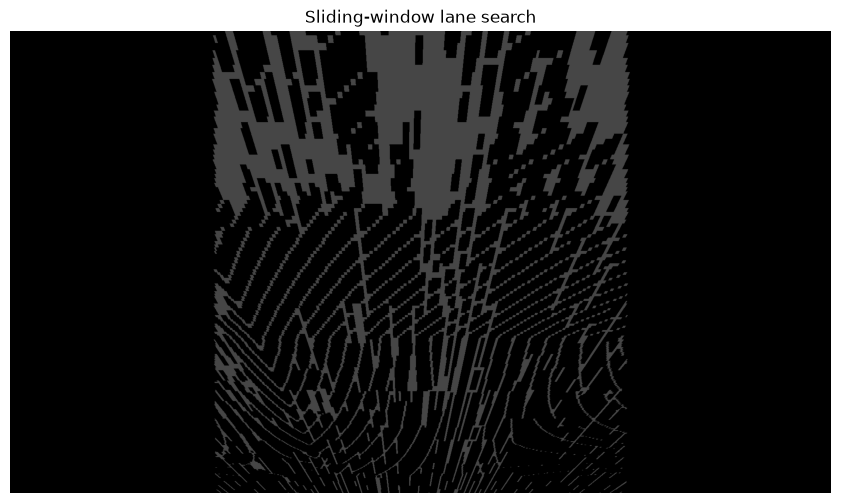

{'left_fit': array([-4.09444426e-05,  3.87628595e-02,  5.21475994e+02]), 'right_fit': array([-1.80400314e-05,  9.69485870e-02,  1.02868185e+03]), 'left_count': 47276, 'right_count': 64780, 'valid': False, 'confidence': 0.7547977408814582, 'mean_residual': 30.14752348258743, 'lane_width_px': 562.7864816137941}
Synthetic lane smoke test passed.


In [6]:
def sliding_window_search(binary, config=CONFIG, windows=9, margin=None, min_pixels=50):
    height, width = binary.shape[:2]
    margin = margin or max(50, width // 28)
    binary = (binary > 0).astype(np.uint8)
    histogram = np.sum(binary[height // 2 :, :], axis=0)
    left_start, left_end = int(width * 0.12), int(width * 0.42)
    right_start, right_end = int(width * 0.58), int(width * 0.88)
    left_current = int(np.argmax(histogram[left_start:left_end]) + left_start)
    right_current = int(np.argmax(histogram[right_start:right_end]) + right_start)

    nonzero_y, nonzero_x = binary.nonzero()
    window_height = max(1, height // windows)
    left_indices, right_indices = [], []
    for window in range(windows):
        y_low, y_high = height - (window + 1) * window_height, height - window * window_height
        left_bounds = (left_current - margin, left_current + margin)
        right_bounds = (right_current - margin, right_current + margin)
        left_found = ((nonzero_y >= y_low) & (nonzero_y < y_high) &
                      (nonzero_x >= left_bounds[0]) & (nonzero_x < left_bounds[1])).nonzero()[0]
        right_found = ((nonzero_y >= y_low) & (nonzero_y < y_high) &
                       (nonzero_x >= right_bounds[0]) & (nonzero_x < right_bounds[1])).nonzero()[0]
        left_indices.append(left_found)
        right_indices.append(right_found)
        if len(left_found) >= min_pixels:
            left_current = int(np.mean(nonzero_x[left_found]))
        if len(right_found) >= min_pixels:
            right_current = int(np.mean(nonzero_x[right_found]))

    left_indices, right_indices = np.concatenate(left_indices), np.concatenate(right_indices)
    left_x, left_y = nonzero_x[left_indices], nonzero_y[left_indices]
    right_x, right_y = nonzero_x[right_indices], nonzero_y[right_indices]
    visualization = cv2.cvtColor(binary * 70, cv2.COLOR_GRAY2BGR)
    result = {"left_fit": None, "right_fit": None, "left_count": len(left_x),
              "right_count": len(right_x), "valid": False, "confidence": 0.0,
              "visualization": visualization}
    if len(left_x) < 100 or len(right_x) < 100:
        return result

    left_fit, right_fit = np.polyfit(left_y, left_x, 2), np.polyfit(right_y, right_x, 2)
    sample_y = np.linspace(height * 0.35, height - 1, 20)
    lane_widths = np.polyval(right_fit, sample_y) - np.polyval(left_fit, sample_y)
    residual = (np.mean(np.abs(left_x - np.polyval(left_fit, left_y))) +
                np.mean(np.abs(right_x - np.polyval(right_fit, right_y)))) / 2
    width_ok = (np.all(lane_widths >= config.lane_width_min * width) and
                np.all(lane_widths <= config.lane_width_max * width) and
                np.ptp(lane_widths) <= 0.30 * width)
    valid = bool(width_ok and residual <= 30)
    confidence = np.clip(0.65 * min(1.0, min(len(left_x), len(right_x)) / 1200) +
                         0.35 * np.exp(-residual / 25), 0, 1)

    if valid:
        visualization[nonzero_y[left_indices], nonzero_x[left_indices]] = (255, 0, 0)
        visualization[nonzero_y[right_indices], nonzero_x[right_indices]] = (0, 255, 0)
        plot_y = np.arange(height, dtype=np.int32)
        for fit, color in ((left_fit, (255, 0, 0)), (right_fit, (0, 255, 0))):
            curve = np.column_stack((np.polyval(fit, plot_y), plot_y)).astype(np.int32)
            cv2.polylines(visualization, [curve], False, color, 4)

    result.update({"left_fit": left_fit, "right_fit": right_fit,
                   "valid": valid, "confidence": float(confidence),
                   "mean_residual": float(residual),
                   "lane_width_px": float(np.mean(lane_widths)),
                   "visualization": visualization})
    return result


search_result = sliding_window_search(birdseye_mask)
show_image(bgr_to_rgb(search_result["visualization"]), "Sliding-window lane search")
print({key: value for key, value in search_result.items() if key != "visualization"})

synthetic_mask = np.zeros((720, 1280), dtype=np.uint8)
synthetic_y = np.arange(260, 720)
for center_x in (330, 930):
    curve_x = center_x + 0.00015 * (synthetic_y - 500) ** 2
    for y_value, x_value in zip(synthetic_y, curve_x.astype(int)):
        cv2.circle(synthetic_mask, (x_value, int(y_value)), 5, 255, -1)
synthetic_result = sliding_window_search(synthetic_mask)
assert synthetic_result["valid"], "Synthetic lane smoke test did not pass geometry checks"
print("Synthetic lane smoke test passed.")

## 6. Temporal Smoothing and Lane Overlay

I carry accepted fits through a short history and average them to reduce frame-to-frame jumps. If detection briefly fails, the last fit can be shown as an orange dashed uncertain estimate. The notebook maps the curves back to the camera view, labels the left boundary blue and the right green, adds approximate curvature and offset text, and writes annotated and diagnostic videos. It also keeps a few frames for the screenshot section.

**Assumptions:** The camera view and frame dimensions do not change during a clip. The ROI is calibrated for this camera, while curvature and offset use approximate lane-width and visible-road-length scales. The displayed confidence is a heuristic, not a probability.

**Complexity:** Each frame is filtered, warped, searched, fitted, and drawn, so total work grows with the number of frames and the image size. The perspective matrices are computed once per video, and only selected diagnostic frames are kept in memory.

In [13]:
class LaneTracker:
    def __init__(self, width, height, history_size=8, max_misses=12):
        self.width, self.height = width, height
        self.left_history = deque(maxlen=history_size)
        self.right_history = deque(maxlen=history_size)
        self.max_misses, self.misses = max_misses, 0
        self.confidence, self.lane_width = 0.0, width * 0.5

    def update(self, result):
        accepted = result["valid"]
        consistency = 1.0
        left, right = result["left_fit"], result["right_fit"]
        if accepted and self.left_history:
            y = np.array([0.45, 0.70, 0.95]) * self.height
            old_left, old_right = np.mean(self.left_history, axis=0), np.mean(self.right_history, axis=0)
            shift = np.mean(np.abs(np.polyval(left, y) - np.polyval(old_left, y)) +
                            np.abs(np.polyval(right, y) - np.polyval(old_right, y))) / 2
            consistency = np.exp(-shift / max(1.0, self.width * 0.08))
            accepted = consistency >= 0.20

        if accepted:
            self.left_history.append(left)
            self.right_history.append(right)
            self.misses = 0
            self.confidence = result["confidence"] * consistency
            self.lane_width = result.get("lane_width_px", self.lane_width)
        else:
            self.misses += 1

        if not self.left_history or self.misses > self.max_misses:
            return None, None, False, 0.0, self.lane_width
        left, right = np.mean(self.left_history, axis=0), np.mean(self.right_history, axis=0)
        confidence = self.confidence if accepted else self.confidence * 0.5
        return left, right, accepted, confidence, self.lane_width


def estimate_lane_metrics(width, height, left_fit, right_fit, lane_width_px):
    if left_fit is None or right_fit is None or lane_width_px <= 0:
        return None, None
    x_scale, y_scale = 3.7 / lane_width_px, 30.0 / height
    y_eval = (height - 1) * y_scale
    radii = []
    for fit in (left_fit, right_fit):
        a, b = fit[0] * x_scale / y_scale**2, fit[1] * x_scale / y_scale
        slope = 2 * a * y_eval + b
        radii.append(float("inf") if abs(2 * a) < 1e-9 else (1 + slope**2)**1.5 / abs(2 * a))
    center = (np.polyval(left_fit, height - 1) + np.polyval(right_fit, height - 1)) / 2
    return float(np.mean(radii)), float((width / 2 - center) * x_scale)


def draw_curve(image, points, color, dashed=False, thickness=6):
    points = np.round(points).astype(np.int32)
    if not dashed:
        cv2.polylines(image, [points[:, None, :]], False, color, thickness)
    else:
        for start in range(0, len(points) - 1, 12):
            if (start // 12) % 2 == 0:
                cv2.line(image, tuple(points[start]), tuple(points[min(start + 6, len(points) - 1)]), color, thickness)


def annotate_frame(frame, fits, detected, confidence, lane_width, inverse):
    height, width = frame.shape[:2]
    left, right = fits
    annotated = frame.copy()
    if left is not None and right is not None:
        y = np.linspace(0, height - 1, 90)
        curves = [np.column_stack((np.clip(np.polyval(fit, y), 0, width - 1), y)).astype(np.float32)
                  for fit in (left, right)]
        curves = [cv2.perspectiveTransform(curve[:, None, :], inverse).reshape(-1, 2)
                  for curve in curves]
        polygon = np.vstack((curves[0], curves[1][::-1])).round().astype(np.int32)
        overlay = np.zeros_like(frame)
        fill = (70, 55, 0) if detected else (0, 70, 100)
        cv2.fillPoly(overlay, [polygon], fill)
        annotated = cv2.addWeighted(frame, 1.0, overlay, 0.22, 0)
        colors = ((255, 0, 0), (0, 255, 0)) if detected else ((0, 165, 255),) * 2
        for curve, color in zip(curves, colors):
            draw_curve(annotated, curve, color, dashed=not detected)

    curvature, offset = estimate_lane_metrics(width, height, left, right, lane_width)
    if detected:
        statuses = (("LEFT LANE DETECTED", (255, 0, 0)),
                    ("RIGHT LANE DETECTED", (0, 255, 0)))
    else:
        message = "UNCERTAIN / CARRIED" if left is not None else "NO LANE FIT"
        statuses = ((message, (0, 165, 255)),)
    for line, (text, color) in enumerate(statuses):
        cv2.putText(annotated, text, (24, 38 + 30 * line), cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, color, 2, cv2.LINE_AA)
    text_y = 38 + 30 * len(statuses)
    cv2.putText(annotated, f"Heuristic confidence: {confidence:.2f}", (24, text_y),
                cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2, cv2.LINE_AA)
    if curvature is not None:
        curve_text = "inf" if np.isinf(curvature) else f"{curvature:.0f} m"
        cv2.putText(annotated, f"Approx. curvature: {curve_text} | offset: {offset:+.2f} m",
                    (24, text_y + 30), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)
    return annotated


def diagnostic_grid(frame, mask, search, annotated):
    height, width = frame.shape[:2]
    roi_view = frame.copy()
    cv2.polylines(roi_view, roi_vertices(width, height), True, (0, 255, 255), 3)
    panels = [roi_view, cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR), search, annotated]
    panels = [cv2.resize(panel, (width // 2, height // 2)) for panel in panels]
    return np.vstack((np.hstack(panels[:2]), np.hstack(panels[2:])))


def process_frame(frame, tracker, matrices):
    forward, inverse = matrices
    mask, _ = gradient_lane_mask(frame)
    search = sliding_window_search(warp_to_birdseye(mask, forward))
    fits = tracker.update(search)
    annotated = annotate_frame(frame, fits[:2], fits[2], fits[3], fits[4], inverse)
    return annotated, diagnostic_grid(frame, mask, search["visualization"], annotated)


def process_video(video_path, frame_limit=FRAME_LIMIT):
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f"OpenCV could not open {video_path}")
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = capture.get(cv2.CAP_PROP_FPS) or 25.0
    total = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    count = min(total, frame_limit) if frame_limit is not None and total else total
    samples_at = {0, count // 2, count - 1} if count > 1 else {0}
    annotated_path = OUTPUT_DIR / f"{video_path.stem}_lka.mp4"
    diagnostic_path = OUTPUT_DIR / f"{video_path.stem}_diagnostic.mp4"
    codec = cv2.VideoWriter_fourcc(*"mp4v")
    writers = [cv2.VideoWriter(str(path), codec, fps, (width, height))
               for path in (annotated_path, diagnostic_path)]
    if not all(writer.isOpened() for writer in writers):
        capture.release()
        for writer in writers:
            writer.release()
        raise RuntimeError("OpenCV could not create the MP4 output files")

    tracker = LaneTracker(width, height)
    matrices = perspective_matrices(width, height)
    samples, frame_number = [], 0
    try:
        while frame_limit is None or frame_number < frame_limit:
            ok, frame = capture.read()
            if not ok:
                break
            annotated, grid = process_frame(frame, tracker, matrices)
            writers[0].write(annotated)
            writers[1].write(grid)
            if frame_number in samples_at:
                samples.append((frame_number, grid.copy()))
            frame_number += 1
    finally:
        capture.release()
        for writer in writers:
            writer.release()

    return {"input": video_path, "annotated": annotated_path, "diagnostic": diagnostic_path,
            "frames_written": frame_number, "samples": samples}


video_paths = sorted(INPUT_DIR.glob("*.mp4")) or [selected_video]
run_results = {path.stem: process_video(path) for path in video_paths}
for result in run_results.values():
    print(f"{result['input'].name}: {result['frames_written']} frames")
    print(f"  Annotated: {result['annotated']}\n  Diagnostic: {result['diagnostic']}")

road-video-dubai.mp4: 180 frames
  Annotated: /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos/road-video-dubai_lka.mp4
  Diagnostic: /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos/road-video-dubai_diagnostic.mp4


## 7. Diagnostics and Screenshots

I add a small title strip to each saved diagnostic grid, write the grids as PNG files in `output_videos/`, and display them in the notebook. Each image puts the camera ROI, gradient mask, bird's-eye search, and final overlay side by side for one timestamp.

**Assumptions:** The processing block has already run and stored sample grids in `run_results`. These are selected examples for inspection, not a complete or statistically representative evaluation.

**Complexity:** Only a few stored images are resized, labeled, and written. The work is proportional to the total pixels in those sample grids, not the length of the video.

Saved road-video-dubai, frame 0: /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos/road-video-dubai_diagnostic_frame_000000.png


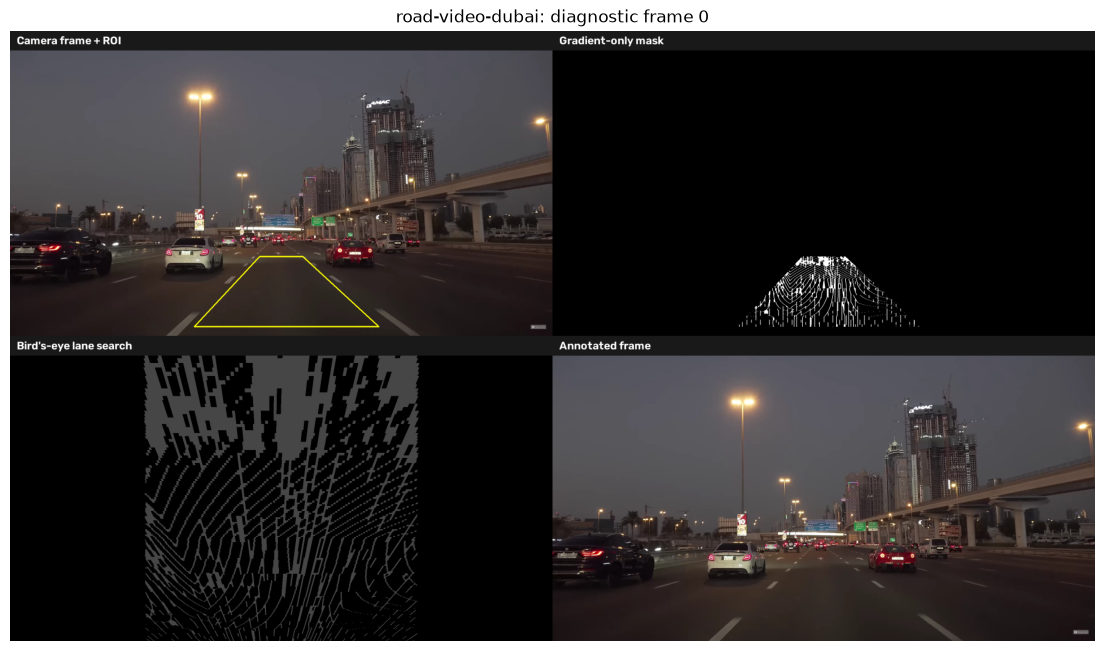

Saved road-video-dubai, frame 90: /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos/road-video-dubai_diagnostic_frame_000090.png


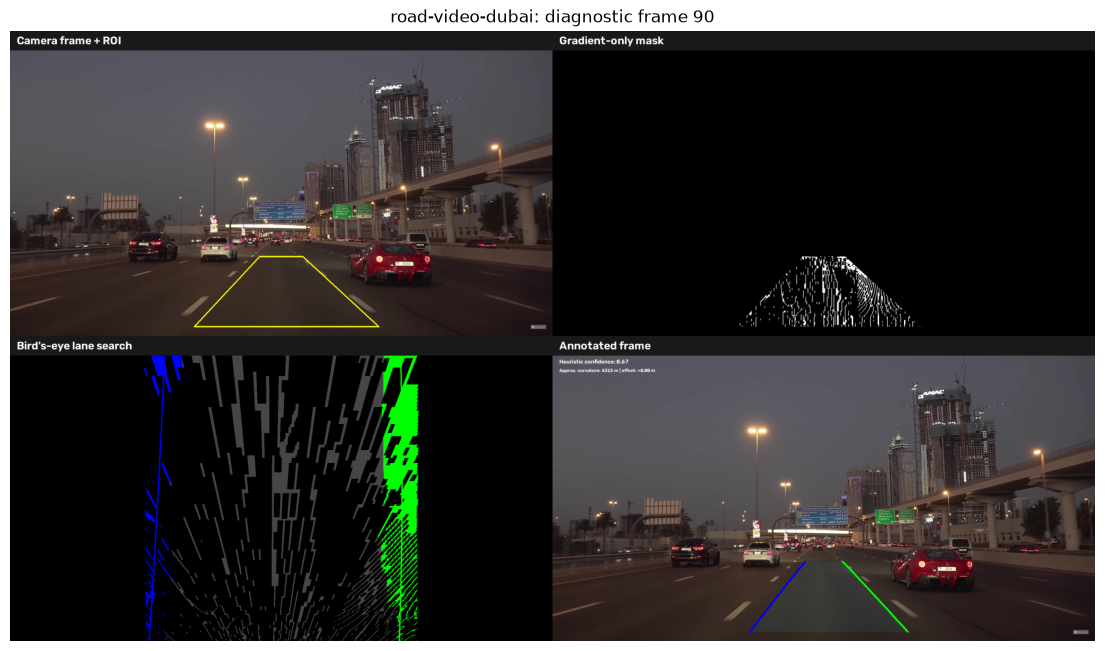

Saved road-video-dubai, frame 179: /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos/road-video-dubai_diagnostic_frame_000179.png


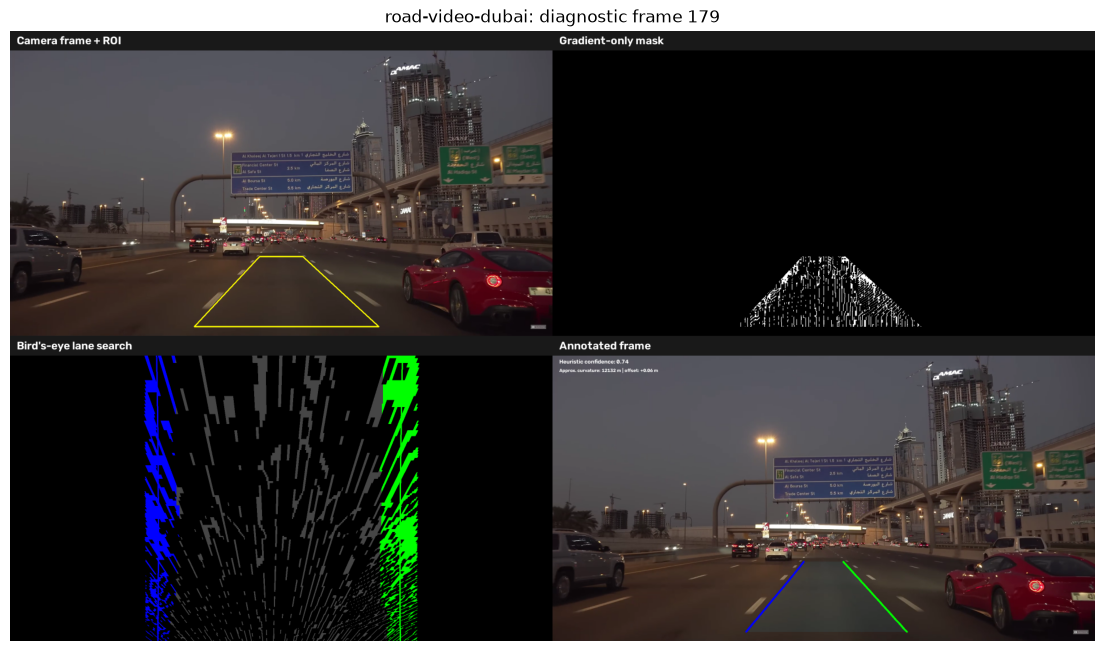

Saved 3 diagnostic screenshot(s) in /Users/rireri/Desktop/Work space/Lane_Keeping VA/output_videos.


In [8]:
def add_panel_labels(grid):
    labeled = grid.copy()
    height, width = labeled.shape[:2]
    half_height, half_width = height // 2, width // 2
    labels = [
        ("Camera frame + ROI", 0, 0),
        ("Gradient-only mask", half_width, 0),
        ("Bird's-eye lane search", 0, half_height),
        ("Annotated frame", half_width, half_height),
    ]
    for text, x, y in labels:
        cv2.rectangle(labeled, (x, y), (x + half_width, y + 34), (25, 25, 25), -1)
        cv2.putText(labeled, text, (x + 12, y + 24), cv2.FONT_HERSHEY_SIMPLEX,
                    0.65, (255, 255, 255), 2, cv2.LINE_AA)
    return labeled


saved_screenshots = []
for video_name, result in run_results.items():
    for frame_number, grid in result["samples"]:
        labeled_grid = add_panel_labels(grid)
        screenshot_path = OUTPUT_DIR / f"{video_name}_diagnostic_frame_{frame_number:06d}.png"
        if not cv2.imwrite(str(screenshot_path), labeled_grid):
            raise IOError(f"Could not save screenshot to {screenshot_path}")
        saved_screenshots.append((video_name, frame_number, screenshot_path, labeled_grid))

for video_name, frame_number, screenshot_path, image in saved_screenshots:
    print(f"Saved {video_name}, frame {frame_number}: {screenshot_path}")
    show_image(bgr_to_rgb(image), f"{video_name}: diagnostic frame {frame_number}", figsize=(14, 8))

print(f"Saved {len(saved_screenshots)} diagnostic screenshot(s) in {OUTPUT_DIR}.")

## Evaluation and Limitations

When I review the outputs, I should note both frames where the curves follow visible paint and frames where detection fails or becomes uncertain. This detector uses grayscale edges only, so cars, lights, and barriers can still create confusing evidence. The ROI and search bands are tuned to `road-video-dubai.mp4` and need to be checked again for a different camera view.

The confidence score is heuristic. Curvature and lateral offset are approximate because they assume a 3.7 m lane width and a 30 m visible road length. Without labeled lane boundaries, I should describe results qualitatively rather than report an accuracy score. Set `FRAME_LIMIT = None` and rerun the video-processing block to analyze the full clip.

This notebook is for offline visual analysis only. It must not be connected to vehicle controls or used for safety decisions.